Loan Approval Prediction Using Machine Learning


1.] Project introduction
Project title: Loan Approval Prediction Using Machine Learning

Problem statement: Banks and financial institutions receive many loan applications. Reviewing each application requires
examining details such as the applicant's income, employment experience, credit score, loan amount and loan purpose.
This project uses supervised machine learning to predict whether a loan application is likely to be approved or rejected.

Objective: Build and evaluate a Decision Tree Classifier that predicts the loan status from applicant and loan-related information.

Target variable: loan_status
- 0 = Rejected
- 1 = Approved
Important: Confirm that the dataset uses this exact target encoding before interpreting the results. If the dataset uses a different mapping, update the labels in the notebook.

2.]Project workflow

1.Import the required Python libraries.
2. Load and understand the dataset.
3. Clean the data and handle invalid or missing values.
4. Perform Exploratory Data Analysis (EDA) and visualize patterns.
5. Separate input features (X) and target (y).
6. Split the data into training and testing sets.
7. Handle missing values and encode categorical features.
8. Train a Decision Tree Classifier.
9. Evaluate the model using accuracy, precision, recall, F1-score and a confusion matrix.
10. Review feature importance and make a sample prediction.

3.]Dataset requirements
Place loan_data.csv in the same folder as this notebook before running it. The dataset must contain a target column named loan_status 
\and the applicant/loan feature columns used in the code. The notebook prints the actual dataset columns and dimensions so that the
report can describe the real dataset
rather than assumed values.
    
Dataset source: Dataset: Loan Approval Classification Dataset, Kaggle (taweilo). Link: https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data. Size: 45,000 rows × 14 columns. Target: loan_status (1 = approved, 0 = rejected).

4.] Algorithm used
A Decision Tree Classifier is a supervised machine learning algorithm used for classification.
It learns decision rules by splitting the dataset based on feature values. Each internal node represents a decision, 
 each branch represents an outcome, and each leaf gives a predicted class.

The model is configured with max_depth=8 to limit tree depth and class_weight="balanced" to help account for class imbalance.
Decision Trees do not require feature scaling. Categorical columns are converted into numeric indicator columns 
using one-hot encoding (pandas.get_dummies).

5.] Evaluation methods
- Accuracy: Overall proportion of correct predictions.
- Precision: Of the applications predicted as approved, how many were actually approved.
- Recall: Of the actually approved applications, how many the model identified.
- F1-score: Harmonic mean of precision and recall.
- Confusion matrix: Counts correct and incorrect predictions for each class.
- Train vs test accuracy: Helps identify a possible gap that may indicate overfitting.

LOAN APPROVAL PREDICTION USING DECISION TREE CLASSIFIER

In [3]:
# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [5]:
df = pd.read_csv("loan_data.csv")

print("Dataset loaded successfully!")
print("Dataset source: Add your original Kaggle/source URL in the project report.")

print("Dataset Shape:", df.shape)

print("\nFirst Five Rows:")
print(df.head())

Dataset loaded successfully!
Dataset source: Add your original Kaggle/source URL in the project report.
Dataset Shape: (45000, 14)

First Five Rows:
   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL     

In [7]:
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nComplete Dataset Summary:")
print(df.describe(include="all"))

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nLoan Status Distribution:")
print(df["loan_status"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_l

In [9]:
# Remove duplicate rows
df = df.drop_duplicates()
df = df[(df["person_age"] <= 100) & (df["person_emp_exp"] <= 60)]

# Convert target column into numeric format
df["loan_status"] = pd.to_numeric(
    df["loan_status"], errors="coerce"
)

# Remove rows with missing target values
df = df.dropna(subset=["loan_status"])

# Keep only valid target values
df = df[df["loan_status"].isin([0, 1])]

# Convert target into integer
df["loan_status"] = df["loan_status"].astype(int)

# Remove columns containing only missing values
df = df.dropna(axis=1, how="all")

print("\nData Cleaning Completed!")

print("Updated Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Data Cleaning Completed!
Updated Dataset Shape: (44990, 14)

Missing Values After Cleaning:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64


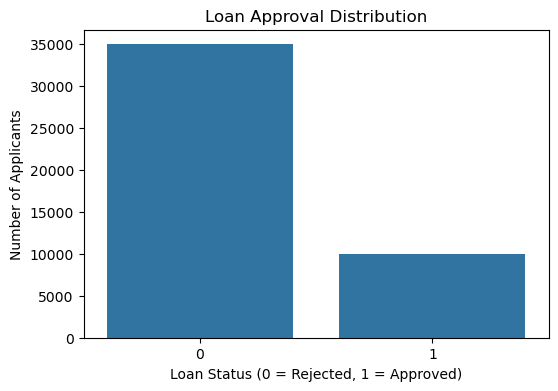

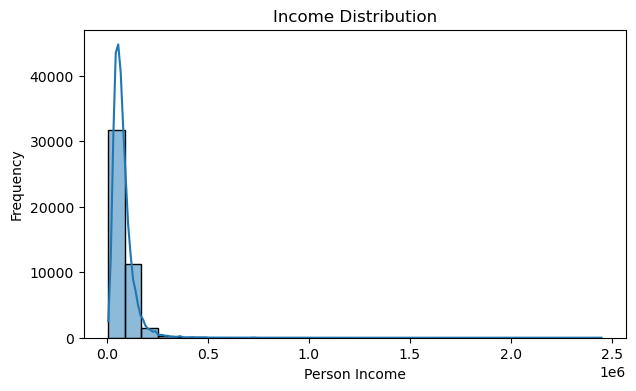

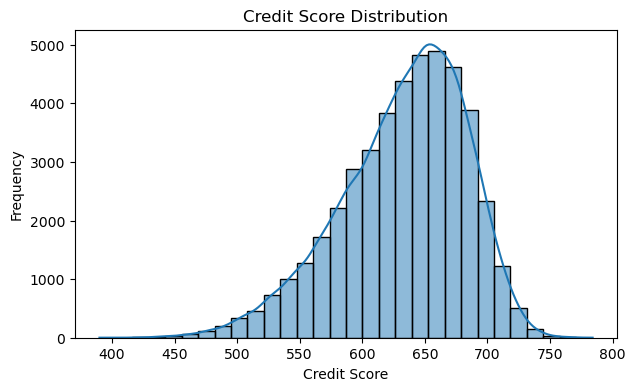

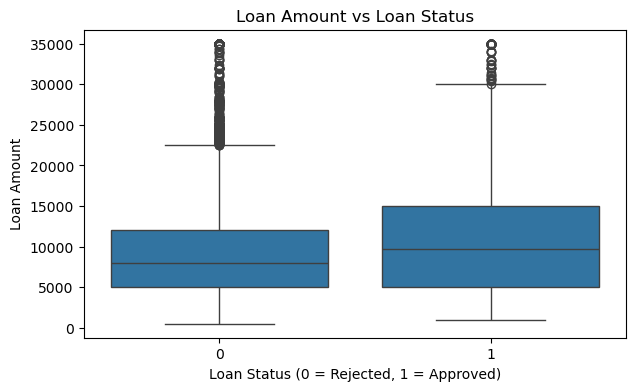

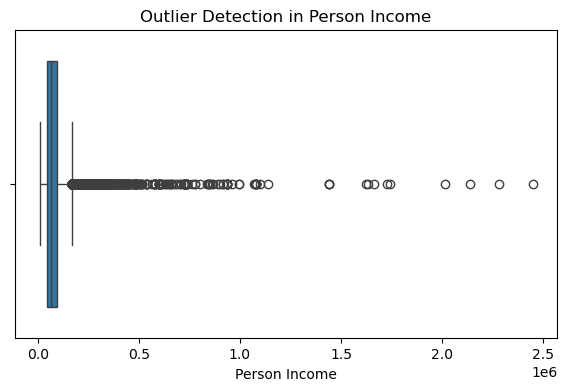

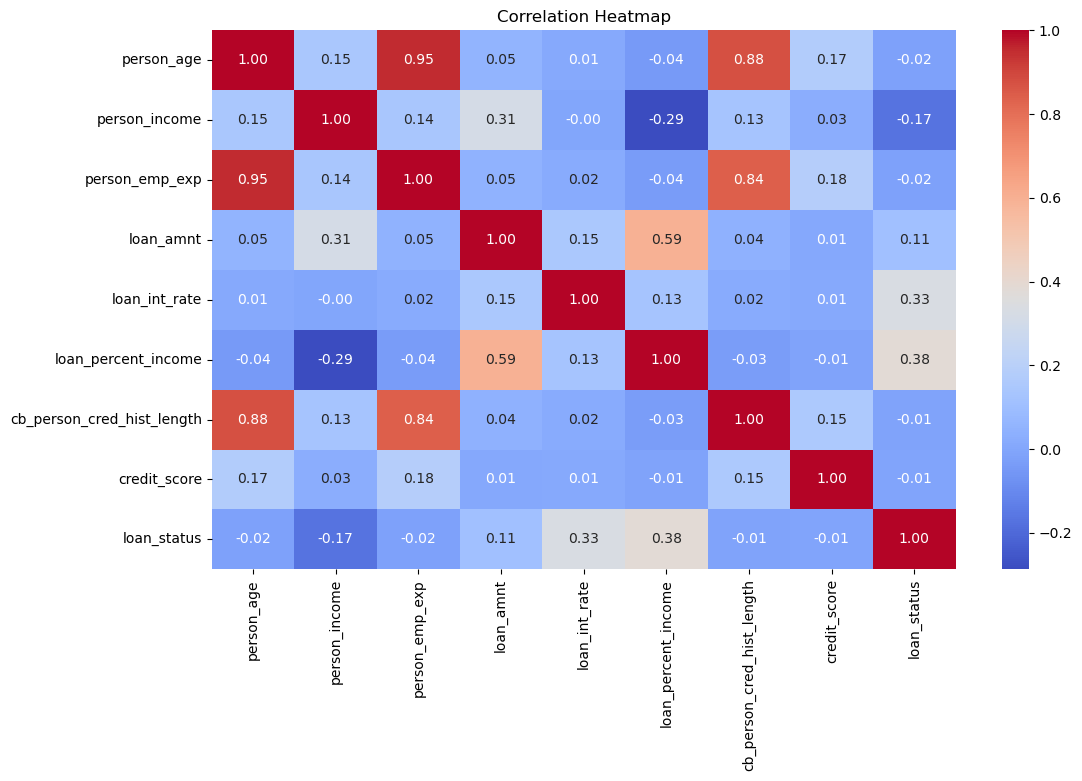

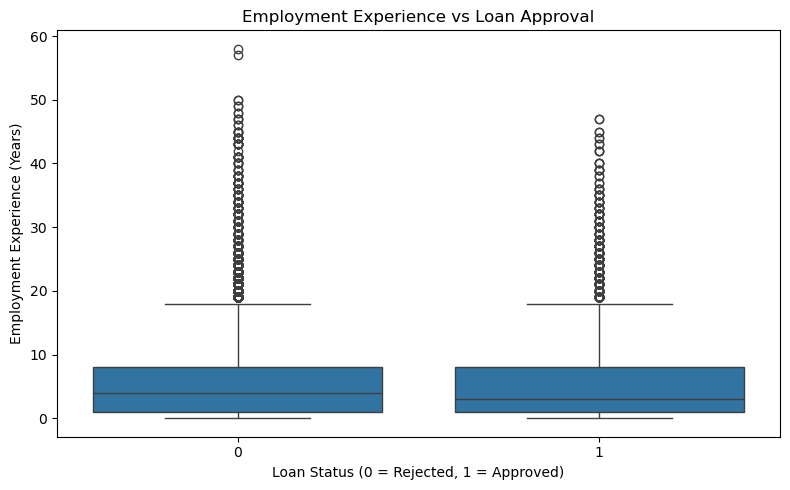

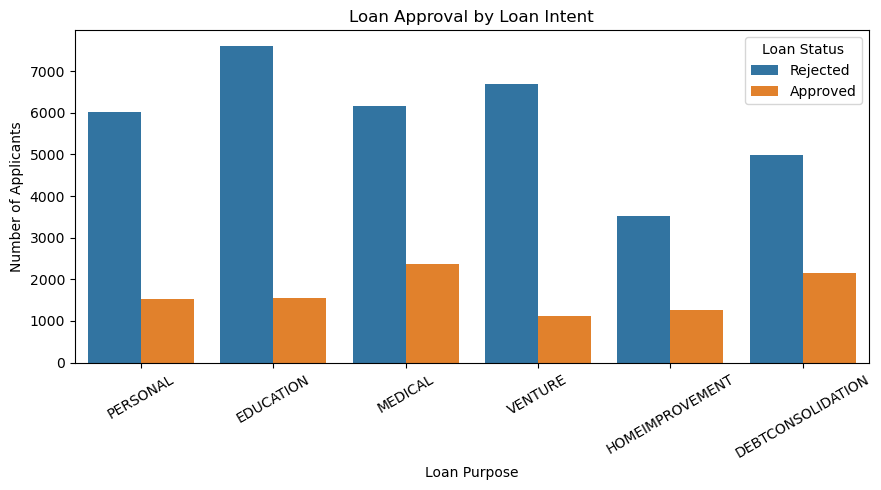

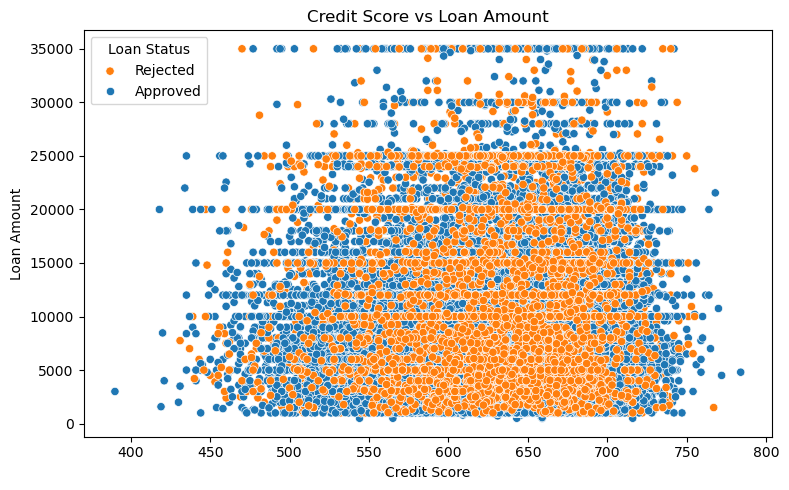

In [11]:
# A. Loan Approval Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applicants")

plt.show()


# B. Income Distribution

plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="person_income",
    bins=30,
    kde=True
)

plt.title("Income Distribution")
plt.xlabel("Person Income")
plt.ylabel("Frequency")

plt.show()


# C. Credit Score Distribution

plt.figure(figsize=(7, 4))

sns.histplot(
    data=df,
    x="credit_score",
    bins=30,
    kde=True
)

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Frequency")

plt.show()


# D. Loan Amount vs Loan Status

plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="loan_status",
    y="loan_amnt"
)

plt.title("Loan Amount vs Loan Status")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Loan Amount")

plt.show()


# E. Outlier Detection

plt.figure(figsize=(7, 4))

sns.boxplot(x=df["person_income"])

plt.title("Outlier Detection in Person Income")
plt.xlabel("Person Income")

plt.show()


# F. Correlation Heatmap

plt.figure(figsize=(12, 7))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# G. Employment Experience vs Loan Status
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="loan_status",
    y="person_emp_exp"
)
plt.title("Employment Experience vs Loan Approval")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Employment Experience (Years)")
plt.tight_layout()
plt.show()


# H. Loan Approval by Loan Intent
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="loan_intent",
    hue="loan_status"
)
plt.title("Loan Approval by Loan Intent")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=30)
plt.legend(title="Loan Status", labels=["Rejected", "Approved"])
plt.tight_layout()
plt.show()


# I. Credit Score vs Loan Amount
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="credit_score",
    y="loan_amnt",
    hue="loan_status"
)
plt.title("Credit Score vs Loan Amount")
plt.xlabel("Credit Score")
plt.ylabel("Loan Amount")
plt.legend(title="Loan Status", labels=["Rejected", "Approved"])
plt.tight_layout()
plt.show()

In [13]:
# X contains input features
# y contains the target column

X = df.drop("loan_status", axis=1)

y = df["loan_status"]

print("\nInput Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Input Features:
   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.

In [15]:
# 80% training data
# 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)


Training Data Shape: (35992, 13)
Testing Data Shape: (8998, 13)


In [17]:
# Fill numerical missing values using median

numerical_columns = X_train.select_dtypes(
    include="number"
).columns

for column in numerical_columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(median_value)

    X_test[column] = X_test[column].fillna(median_value)


# Fill categorical missing values using mode

categorical_columns = X_train.select_dtypes(
    exclude="number"
).columns

for column in categorical_columns:

    mode_values = X_train[column].mode()

    if not mode_values.empty:

        mode_value = mode_values[0]

        X_train[column] = X_train[column].fillna(mode_value)

        X_test[column] = X_test[column].fillna(mode_value)


print("\nMissing Values Handled Successfully!")

print("Training Missing Values:", X_train.isnull().sum().sum())

print("Testing Missing Values:", X_test.isnull().sum().sum())


Missing Values Handled Successfully!
Training Missing Values: 0
Testing Missing Values: 0


In [19]:
# Convert categorical columns into numerical columns

X_train = pd.get_dummies(
    X_train,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True
)

# Make sure both datasets have the same columns

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("\nFeature Encoding Completed!")

print("Training Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)


Feature Encoding Completed!
Training Data Shape: (35992, 22)
Testing Data Shape: (8998, 22)


In [21]:
model = DecisionTreeClassifier(
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

# Train the model

model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")


Decision Tree Model Trained Successfully!


In [23]:
y_pred = model.predict(X_test)

print("\nActual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])


Actual Values:
[0 1 0 0 0 0 0 0 0 0]

Predicted Values:
[0 1 0 1 0 0 0 0 0 0]


In [25]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("\nMODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall:", round(recall * 100, 2), "%")

print("F1 Score:", round(f1 * 100, 2), "%")
print("Train accuracy:", round(model.score(X_train, y_train) * 100, 2), "%")
print("Test accuracy :", round(model.score(X_test, y_test) * 100, 2), "%")


MODEL EVALUATION RESULTS
------------------------
Accuracy: 88.28 %
Precision: 67.84 %
Recall: 89.85 %
F1 Score: 77.31 %
Train accuracy: 89.07 %
Test accuracy : 88.28 %


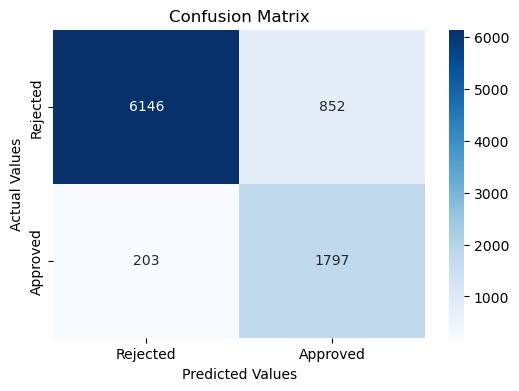

In [27]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [29]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Rejected", "Approved"],
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

    Rejected       0.97      0.88      0.92      6998
    Approved       0.68      0.90      0.77      2000

    accuracy                           0.88      8998
   macro avg       0.82      0.89      0.85      8998
weighted avg       0.90      0.88      0.89      8998




Feature Importance:
                               Feature    Importance
21  previous_loan_defaults_on_file_Yes  6.715889e-01
4                        loan_int_rate  1.226877e-01
5                  loan_percent_income  8.190377e-02
1                        person_income  6.868893e-02
14           person_home_ownership_OWN  1.496003e-02
15          person_home_ownership_RENT  1.267453e-02
20                 loan_intent_VENTURE  7.951626e-03
17         loan_intent_HOMEIMPROVEMENT  6.563511e-03
7                         credit_score  6.362791e-03
16               loan_intent_EDUCATION  2.238041e-03
0                           person_age  1.495105e-03
3                            loan_amnt  1.412329e-03
19                loan_intent_PERSONAL  4.874057e-04
2                       person_emp_exp  3.588263e-04
6           cb_person_cred_hist_length  3.326107e-04
11        person_education_High School  2.939313e-04
8                   person_gender_male  5.038281e-15
9            person_educa

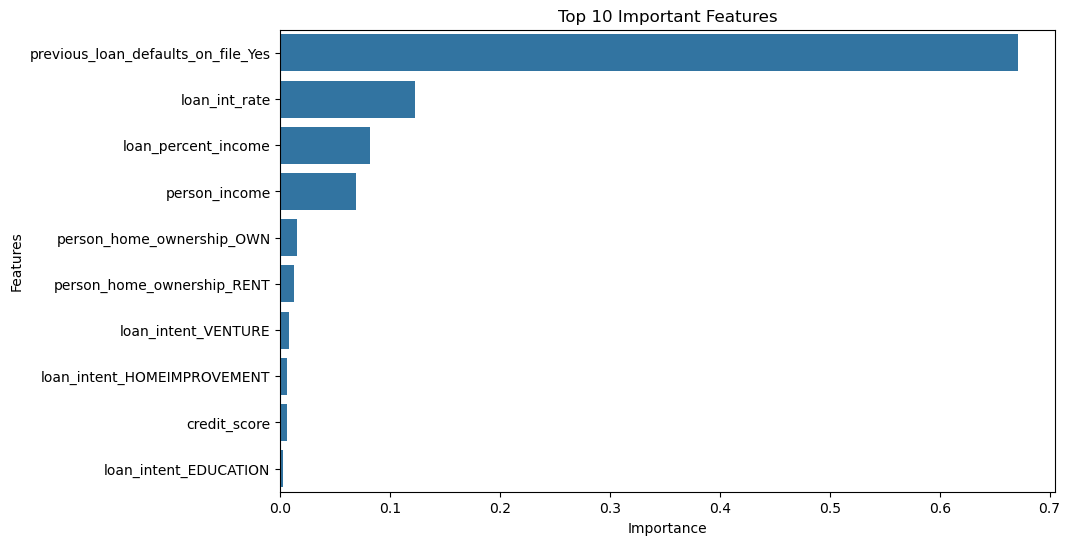

In [31]:
feature_importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")

print(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

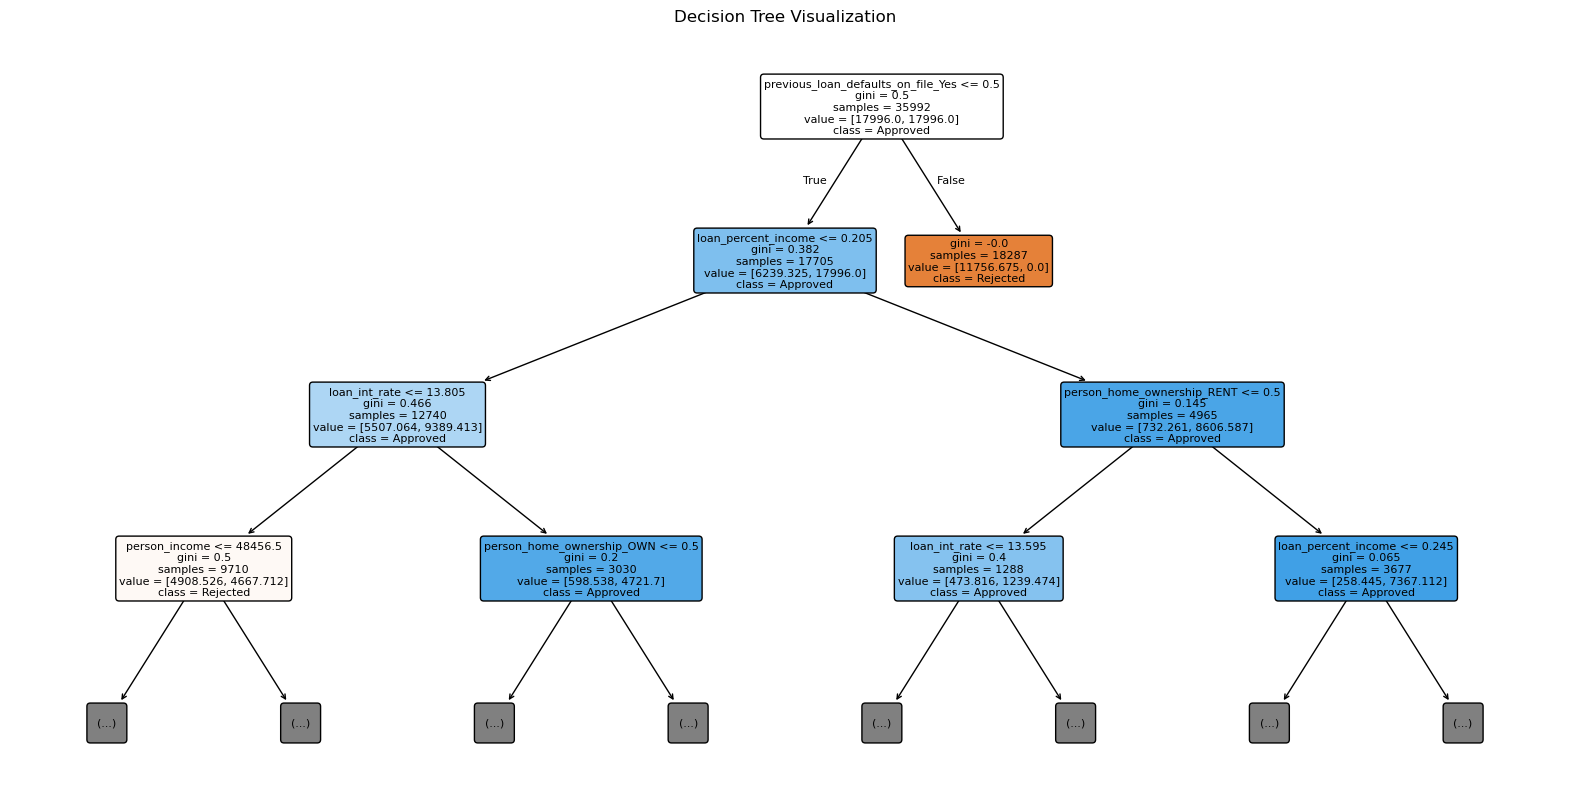

In [35]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X_train.columns,
    class_names=["Rejected", "Approved"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")

plt.show()

In [37]:
print("\nAvailable Gender Values:")
print(df["person_gender"].unique())

print("\nAvailable Education Values:")
print(df["person_education"].unique())

print("\nAvailable Home Ownership Values:")
print(df["person_home_ownership"].unique())

print("\nAvailable Loan Intent Values:")
print(df["loan_intent"].unique())

print("\nAvailable Previous Default Values:")
print(df["previous_loan_defaults_on_file"].unique())


Available Gender Values:
['female' 'male']

Available Education Values:
['Master' 'High School' 'Bachelor' 'Associate' 'Doctorate']

Available Home Ownership Values:
['RENT' 'OWN' 'MORTGAGE' 'OTHER']

Available Loan Intent Values:
['PERSONAL' 'EDUCATION' 'MEDICAL' 'VENTURE' 'HOMEIMPROVEMENT'
 'DEBTCONSOLIDATION']

Available Previous Default Values:
['No' 'Yes']


In [39]:
# Example applicant details
# Use category values that match your dataset

new_applicant = pd.DataFrame([{

    "person_age": 25,

    "person_gender": "female",

    "person_education": "Bachelor",

    "person_income": 50000,

    "person_emp_exp": 2,

    "person_home_ownership": "RENT",

    "loan_amnt": 10000,

    "loan_intent": "PERSONAL",

    "loan_int_rate": 10.5,

    "loan_percent_income": 0.20,

    "cb_person_cred_hist_length": 4,

    "credit_score": 700,

    "previous_loan_defaults_on_file": "No"

}])


# Convert categorical values into numerical columns

new_applicant = pd.get_dummies(new_applicant)

# Match columns with training data

new_applicant = new_applicant.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Predict loan status

prediction = model.predict(new_applicant)

if prediction[0] == 1:

    print("\nLoan Status: APPROVED")

else:

    print("\nLoan Status: REJECTED")


Loan Status: REJECTED


In [41]:
print("\n===================================")
print("LOAN APPROVAL PREDICTION PROJECT")
print("===================================")

print("Algorithm: Decision Tree Classifier")

print("Dataset Size:", df.shape)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("Accuracy:", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall:", round(recall * 100, 2), "%")

print("F1 Score:", round(f1 * 100, 2), "%")

print("\nProject Completed Successfully!")


LOAN APPROVAL PREDICTION PROJECT
Algorithm: Decision Tree Classifier
Dataset Size: (44990, 14)
Training Records: 35992
Testing Records: 8998
Accuracy: 88.28 %
Precision: 67.84 %
Recall: 89.85 %
F1 Score: 77.31 %

Project Completed Successfully!
